In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))


/kaggle/input/datasets/marianursarescu/ic3-dataset/e02eaac21594c46b3c63e77a70f5887d.nc


In [2]:

import xarray as xr
import glob

files = glob.glob("/kaggle/input/**/*.nc", recursive=True)

print("Fișiere NetCDF găsite:", len(files))
print(files)

if not files:
    raise FileNotFoundError("Nu au fost găsite fișiere .nc")

ds = xr.open_mfdataset(
    files,
    combine="by_coords"
)

print(ds)


Fișiere NetCDF găsite: 1
['/kaggle/input/datasets/marianursarescu/ic3-dataset/e02eaac21594c46b3c63e77a70f5887d.nc']
<xarray.Dataset> Size: 77kB
Dimensions:     (valid_time: 132, latitude: 4, longitude: 7)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 1kB 2015-01-01 ... 2025-12-01
  * latitude    (latitude) float64 32B 44.8 44.7 44.6 44.5
  * longitude   (longitude) float64 56B 23.8 23.9 24.0 24.1 24.2 24.3 24.4
    number      int64 8B ...
    expver      (valid_time) <U4 2kB dask.array<chunksize=(132,), meta=np.ndarray>
Data variables:
    t2m         (valid_time, latitude, longitude) float32 15kB dask.array<chunksize=(132, 4, 7), meta=np.ndarray>
    swvl1       (valid_time, latitude, longitude) float32 15kB dask.array<chunksize=(132, 4, 7), meta=np.ndarray>
    swvl2       (valid_time, latitude, longitude) float32 15kB dask.array<chunksize=(132, 4, 7), meta=np.ndarray>
    pev         (valid_time, latitude, longitude) float32 15kB dask.array<chunksize=(132, 4, 7), meta=np

In [3]:

print("Variabile disponibile:")
for var in ds.data_vars:
    print(var, ds[var].attrs.get("units", "Unitate necunoscută"))

print("\nCoordonate:")
print(ds.coords)

print("\nDimensiuni:")
print(ds.sizes)


Variabile disponibile:
t2m K
swvl1 m**3 m**-3
swvl2 m**3 m**-3
pev m
tp m

Coordonate:
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 1kB 2015-01-01 ... 2025-12-01
  * latitude    (latitude) float64 32B 44.8 44.7 44.6 44.5
  * longitude   (longitude) float64 56B 23.8 23.9 24.0 24.1 24.2 24.3 24.4
    number      int64 8B ...
    expver      (valid_time) <U4 2kB dask.array<chunksize=(132,), meta=np.ndarray>

Dimensiuni:
Frozen({'valid_time': 132, 'latitude': 4, 'longitude': 7})


In [4]:

print("Valori lipsă pentru fiecare variabilă:")

for var in ds.data_vars:
    missing = ds[var].isnull().sum().compute().item()
    total = ds[var].size

    print(f"{var}: {missing}/{total} ({100 * missing / total:.2f}%)")


Valori lipsă pentru fiecare variabilă:
t2m: 0/3696 (0.00%)
swvl1: 0/3696 (0.00%)
swvl2: 0/3696 (0.00%)
pev: 0/3696 (0.00%)
tp: 0/3696 (0.00%)


In [5]:

import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Selectăm variabilele necesare
data = ds[["t2m", "swvl1", "swvl2", "tp", "pev"]].copy()

# Conversia unităților
data["temperature_c"] = data["t2m"] - 273.15
data["precipitation_mm"] = data["tp"] * 1000

# Umiditatea medie a solului pe adâncimea 0-28 cm
data["soil_moisture"] = (
    data["swvl1"] * 7 +
    data["swvl2"] * 21
) / 28

# Media spațială pentru regiunea selectată
regional = data[
    ["temperature_c", "precipitation_mm", "soil_moisture"]
].mean(dim=["latitude", "longitude"])

# Transformare în DataFrame
df = regional.to_dataframe().reset_index()

# Păstrăm doar coloanele necesare
df = df[
    ["valid_time", "temperature_c",
     "precipitation_mm", "soil_moisture"]
]

df = df.rename(columns={"valid_time": "date"})

print(df.head())
print("\nDimensiuni:", df.shape)


        date  temperature_c  precipitation_mm  soil_moisture
0 2015-01-01       0.693826          1.458557       0.394594
1 2015-02-01       1.185168          1.829039       0.398837
2 2015-03-01       5.797917          2.304138       0.393193
3 2015-04-01      10.832206          1.460087       0.345444
4 2015-05-01      17.729858          2.203503       0.334462

Dimensiuni: (132, 4)


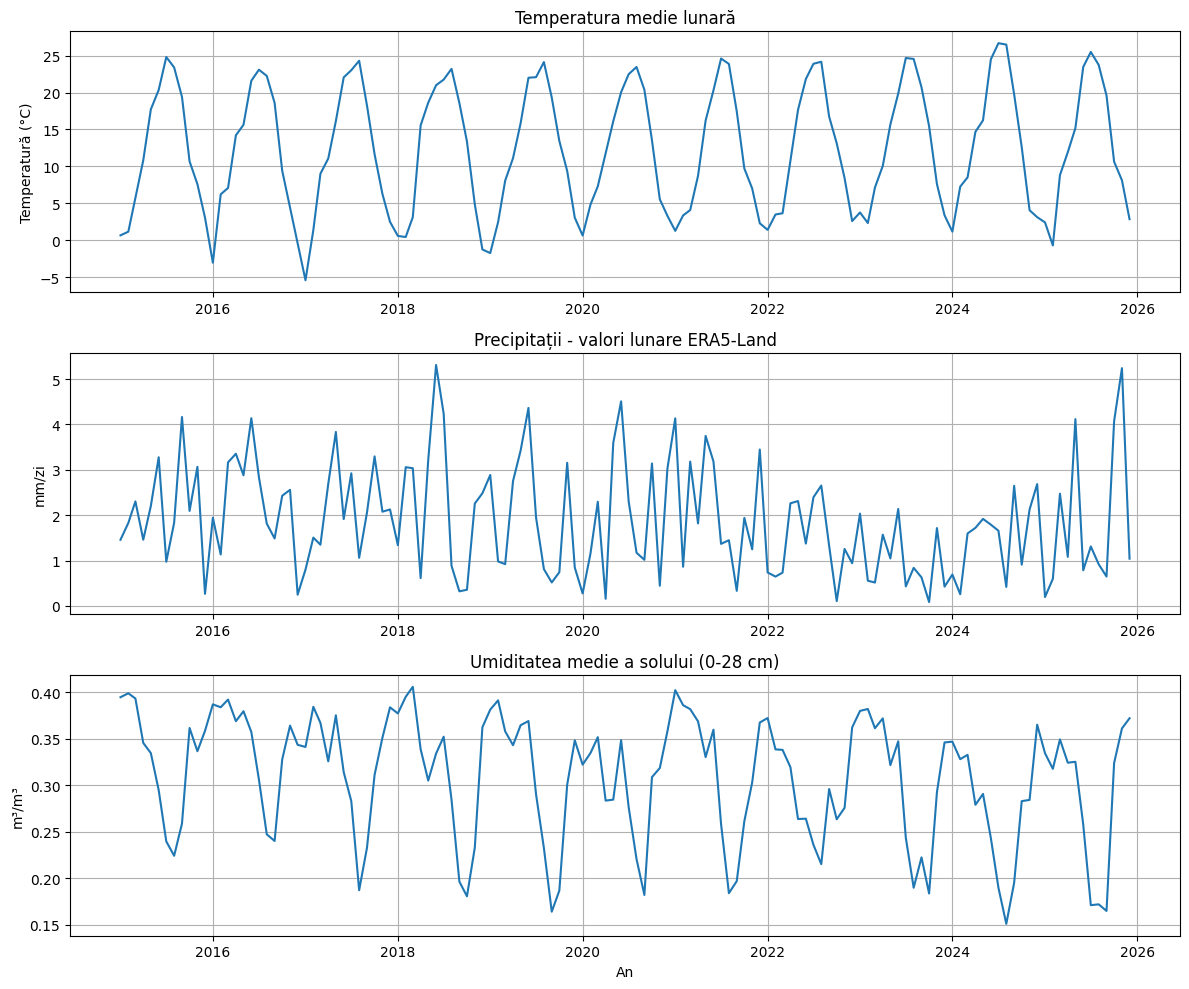

In [6]:

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(df["date"], df["temperature_c"])
axes[0].set_title("Temperatura medie lunară")
axes[0].set_ylabel("Temperatură (°C)")
axes[0].grid(True)

axes[1].plot(df["date"], df["precipitation_mm"])
axes[1].set_title("Precipitații - valori lunare ERA5-Land")
axes[1].set_ylabel("mm/zi")
axes[1].grid(True)

axes[2].plot(df["date"], df["soil_moisture"])
axes[2].set_title("Umiditatea medie a solului (0-28 cm)")
axes[2].set_ylabel("m³/m³")
axes[2].set_xlabel("An")
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [7]:

# Transformăm coloana date în datetime
df["date"] = pd.to_datetime(df["date"])

# Numărul de zile din fiecare lună
df["days_in_month"] = df["date"].dt.days_in_month

# Calculăm totalul lunar al precipitațiilor
df["precipitation_monthly_mm"] = (
    df["precipitation_mm"] * df["days_in_month"]
)

print(df[[
    "date",
    "precipitation_monthly_mm",
    "temperature_c",
    "soil_moisture"
]].head())


        date  precipitation_monthly_mm  temperature_c  soil_moisture
0 2015-01-01                 45.215271       0.693826       0.394594
1 2015-02-01                 51.213105       1.185168       0.398837
2 2015-03-01                 71.428276       5.797917       0.393193
3 2015-04-01                 43.802623      10.832206       0.345444
4 2015-05-01                 68.308582      17.729858       0.334462


In [8]:

# Extragem luna calendaristică
df["month"] = df["date"].dt.month

# Folosim numai perioada de antrenare pentru
# calcularea statisticilor de referință
train_reference = df[df["date"] < "2022-01-01"]

monthly_stats = train_reference.groupby("month")["soil_moisture"].agg(
    mean="mean",
    std="std"
)

# Adăugăm statisticile la întregul set de date
df = df.join(monthly_stats, on="month")

# Calculăm indicele standardizat
df["SSMI"] = (
    (df["soil_moisture"] - df["mean"]) / df["std"]
)

print(df[["date", "soil_moisture", "SSMI"]].head())


        date  soil_moisture      SSMI
0 2015-01-01       0.394594  0.761413
1 2015-02-01       0.398837  0.779442
2 2015-03-01       0.393193  0.731113
3 2015-04-01       0.345444  0.218724
4 2015-05-01       0.334462 -0.126704


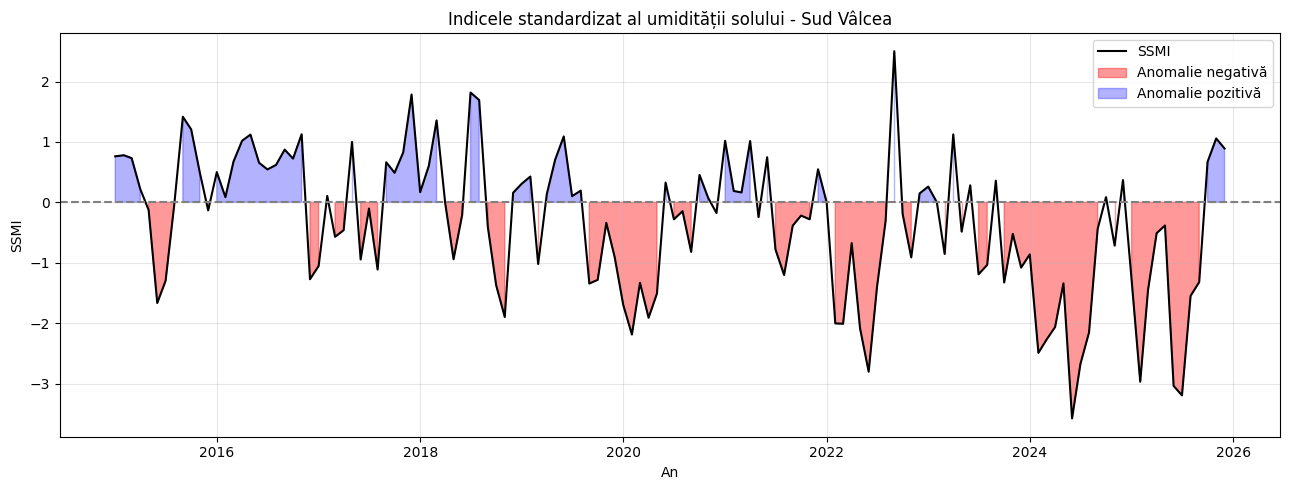

In [9]:

plt.figure(figsize=(13, 5))

plt.plot(
    df["date"],
    df["SSMI"],
    color="black",
    linewidth=1.5,
    label="SSMI"
)

plt.axhline(0, color="gray", linestyle="--")

plt.fill_between(
    df["date"], df["SSMI"], 0,
    where=df["SSMI"] < 0,
    color="red", alpha=0.4,
    label="Anomalie negativă"
)

plt.fill_between(
    df["date"], df["SSMI"], 0,
    where=df["SSMI"] >= 0,
    color="blue", alpha=0.3,
    label="Anomalie pozitivă"
)

plt.title("Indicele standardizat al umidității solului - Sud Vâlcea")
plt.xlabel("An")
plt.ylabel("SSMI")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:

train = df[df["date"] < "2022-01-01"].copy()

val = df[
    (df["date"] >= "2022-01-01") &
    (df["date"] < "2024-01-01")
].copy()

test = df[df["date"] >= "2024-01-01"].copy()

print("Train:", len(train), "luni")
print("Validation:", len(val), "luni")
print("Test:", len(test), "luni")

# Salvăm datele preprocesate
df.to_csv("/kaggle/working/era5_valcea_processed.csv", index=False)


Train: 84 luni
Validation: 24 luni
Test: 24 luni


In [11]:

print("Latitudini:", ds.latitude.values)
print("Longitudini:", ds.longitude.values)

print("\nPerioada:")
print("Start:", str(ds.valid_time.values[0]))
print("Final:", str(ds.valid_time.values[-1]))

print("\nRezoluție spațială:")
print("Latitudine:", abs(float(ds.latitude.diff("latitude").mean())))
print("Longitudine:", abs(float(ds.longitude.diff("longitude").mean())))

print("\nNumăr puncte geografice:",
      ds.sizes["latitude"] * ds.sizes["longitude"])


Latitudini: [44.8 44.7 44.6 44.5]
Longitudini: [23.8 23.9 24.  24.1 24.2 24.3 24.4]

Perioada:
Start: 2015-01-01T00:00:00.000000000
Final: 2025-12-01T00:00:00.000000000

Rezoluție spațială:
Latitudine: 0.09999999999999905
Longitudine: 0.09999999999999964

Număr puncte geografice: 28
